In [5]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
from pathlib import Path
import logging
from datetime import datetime
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from tools.animator import Animator

2026-06-09 11:56:21,470 | 训练全部完成！


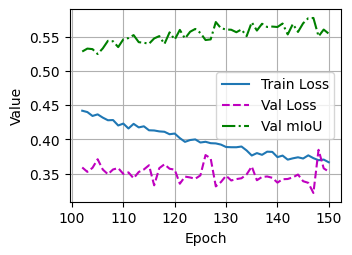

In [ ]:

# ===================== 路径 & 日志初始化 =====================
LOG_ROOT = Path("../logs")
LOG_DIR = LOG_ROOT / "train_log"
WEIGHT_DIR = LOG_ROOT / "weights"
LOG_DIR.mkdir(parents=True, exist_ok=True)
WEIGHT_DIR.mkdir(parents=True, exist_ok=True)

log_time = datetime.now().strftime("%Y%m%d_%H%M%S")
log_file = LOG_DIR / f"train_{log_time}.log"

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(message)s",
    handlers=[
        logging.FileHandler(log_file, encoding="utf-8"),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger()

# =====================  Cityscapes 类别定义 =====================
# Cityscapes 19 类（trainIds 0~18），标注中 255 表示忽略像素
CITYSCAPES_CLASSES = [
    "road", "sidewalk", "building", "wall", "fence", "pole",
    "traffic light", "traffic sign", "vegetation", "terrain", "sky",
    "person", "rider", "car", "truck", "bus", "train",
    "motorcycle", "bicycle"
]
NUM_CLASSES = len(CITYSCAPES_CLASSES)   # 19
IGNORE_INDEX = 255

# =====================  数据集 =====================
class CityscapesDataset(Dataset):
    """Cityscapes 语义分割数据集：leftImg8bit 图像 + gtFine labelTrainIds 标注"""
    def __init__(self, root_dir, split="train", transform=None, label_size=(256, 256)):
        self.root_dir = Path(root_dir)
        self.split = split
        self.transform = transform
        self.label_size = label_size
        img_root = self.root_dir / "leftImg8bit" / split
        gt_root = self.root_dir / "gtFine" / split

        self.samples = []
        for img_path in sorted(img_root.glob("*/*.png")):
            city = img_path.parent.name
            base = img_path.name.replace("_leftImg8bit.png", "")
            label_path = gt_root / city / f"{base}_gtFine_labelTrainIds.png"
            if label_path.exists():
                self.samples.append((img_path, label_path))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label_path = self.samples[idx]
        img = Image.open(img_path).convert("RGB")
        label = Image.open(label_path)

        if self.transform is not None:
            img = self.transform(img)

        label = label.resize(self.label_size, Image.NEAREST)
        label = torch.from_numpy(np.array(label)).long()

        return img, label

# =====================  UNet++ 模型 =====================
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout2d(dropout) if dropout>0 else nn.Identity()
        )
    def forward(self, x):
        return self.conv(x)

class UpBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, 2, stride=2)
    def forward(self, x):
        return self.up(x)

class UNetPlusPlus(nn.Module):
    def __init__(self, in_channels=3, num_classes=NUM_CLASSES, deep_supervision=True, dropout=0.1):
        super().__init__()
        self.deep_supervision = deep_supervision
        filters = [32, 64, 128, 256, 512]

        self.x00 = ConvBlock(in_channels, filters[0], dropout)
        self.x10 = ConvBlock(filters[0], filters[1], dropout)
        self.x20 = ConvBlock(filters[1], filters[2], dropout)
        self.x30 = ConvBlock(filters[2], filters[3], dropout)
        self.x40 = ConvBlock(filters[3], filters[4], dropout)
        self.pool = nn.MaxPool2d(2)

        # j=1
        self.up10 = UpBlock(filters[1], filters[0])
        self.x01 = ConvBlock(filters[0]*2, filters[0], dropout)
        self.up20 = UpBlock(filters[2], filters[1])
        self.x11 = ConvBlock(filters[1]*2, filters[1], dropout)
        self.up30 = UpBlock(filters[3], filters[2])
        self.x21 = ConvBlock(filters[2]*2, filters[2], dropout)
        self.up40 = UpBlock(filters[4], filters[3])
        self.x31 = ConvBlock(filters[3]*2, filters[3], dropout)

        # j=2
        self.up11 = UpBlock(filters[1], filters[0])
        self.x02 = ConvBlock(filters[0]*3, filters[0], dropout)
        self.up21 = UpBlock(filters[2], filters[1])
        self.x12 = ConvBlock(filters[1]*3, filters[1], dropout)
        self.up31 = UpBlock(filters[3], filters[2])
        self.x22 = ConvBlock(filters[2]*3, filters[2], dropout)

        # j=3
        self.up12 = UpBlock(filters[1], filters[0])
        self.x03 = ConvBlock(filters[0]*4, filters[0], dropout)
        self.up22 = UpBlock(filters[2], filters[1])
        self.x13 = ConvBlock(filters[1]*4, filters[1], dropout)

        # j=4
        self.up13 = UpBlock(filters[1], filters[0])
        self.x04 = ConvBlock(filters[0]*5, filters[0], dropout)

        if self.deep_supervision:
            self.out1 = nn.Conv2d(filters[0], num_classes, 1)
            self.out2 = nn.Conv2d(filters[0], num_classes, 1)
            self.out3 = nn.Conv2d(filters[0], num_classes, 1)
            self.out4 = nn.Conv2d(filters[0], num_classes, 1)
        else:
            self.out = nn.Conv2d(filters[0], num_classes, 1)

    def forward(self, x):
        x00 = self.x00(x)
        x10 = self.x10(self.pool(x00))
        x20 = self.x20(self.pool(x10))
        x30 = self.x30(self.pool(x20))
        x40 = self.x40(self.pool(x30))

        x31 = self.x31(torch.cat([x30, self.up40(x40)], dim=1))
        x21 = self.x21(torch.cat([x20, self.up30(x31)], dim=1))
        x11 = self.x11(torch.cat([x10, self.up20(x21)], dim=1))
        x01 = self.x01(torch.cat([x00, self.up10(x10)], dim=1))

        x22 = self.x22(torch.cat([x20, x21, self.up31(x31)], dim=1))
        x12 = self.x12(torch.cat([x10, x11, self.up21(x21)], dim=1))
        x02 = self.x02(torch.cat([x00, x01, self.up11(x11)], dim=1))

        x13 = self.x13(torch.cat([x10, x11, x12, self.up22(x22)], dim=1))
        x03 = self.x03(torch.cat([x00, x01, x02, self.up12(x12)], dim=1))

        x04 = self.x04(torch.cat([x00, x01, x02, x03, self.up13(x13)], dim=1))

        if self.deep_supervision:
            return [self.out1(x01), self.out2(x02), self.out3(x03), self.out4(x04)]
        return self.out(x04)

# =====================  mIoU 计算 =====================
def compute_iou(pred, label, num_classes, ignore_index=IGNORE_INDEX):
    valid = label != ignore_index
    pred, label = pred[valid], label[valid]
    iou_list = []
    for c in range(num_classes):
        p_mask = (pred == c)
        l_mask = (label == c)
        inter = (p_mask & l_mask).sum().float()
        union = (p_mask | l_mask).sum().float()
        if union == 0:
            continue
        iou_list.append(inter / union)
    if len(iou_list) == 0:
        return torch.tensor(0.0)
    return torch.mean(torch.stack(iou_list))

def eval_miou(model, loader, num_classes, device):
    model.eval()
    total_miou = 0.0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = torch.argmax(outputs[-1], dim=1)
            for p, l in zip(preds, labels):
                total_miou += compute_iou(p, l, num_classes)
    return total_miou / len(loader.dataset)

# =====================  训练 =====================
def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    root = "../data/cityscapes"
    batch_size = 16
    epochs = 150
    lr = 1e-4
    num_classes = NUM_CLASSES
    ds_weights = [0.4, 0.3, 0.2, 0.1]
    num_workers = 4

    # 初始化可视化面板：三条曲线
    animator = Animator(
        xlabel='Epoch',
        ylabel='Value',
        legend=['Train Loss', 'Val Loss', 'Val mIoU'],
    )

    logger.info("=" * 60)
    logger.info(f"训练开始 | 设备: {device} | BatchSize: {batch_size} | LR: {lr} | Epochs: {epochs}")
    logger.info("=" * 60)

    # 数据预处理
    transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    train_set = CityscapesDataset(root, split="train", transform=transform)
    val_set = CityscapesDataset(root, split="val", transform=transform)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    model = UNetPlusPlus(in_channels=3, num_classes=num_classes, deep_supervision=True).to(device)
    
    # 加载权重 继续训练
    # weight_path = WEIGHT_DIR / f"unetpp_ep100.pth"
    # checkpoint = torch.load(weight_path, map_location=device)
    # model.load_state_dict(checkpoint)
    # logger.info(f"成功加载权重: {weight_path}")

    criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    # for epoch in range(101,150):
    for epoch in range(epochs):
        # 训练阶段
        model.train()
        train_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)

            loss = 0.0
            for out, w in zip(outputs, ds_weights):
                loss += w * criterion(out, labels)

            loss.backward()
            optimizer.step()
            train_loss += loss.item() * imgs.size(0)
        train_loss /= len(train_set)

        # 验证阶段
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs[-1], labels)
                val_loss += loss.item() * imgs.size(0)
        val_loss /= len(val_set)

        # 计算mIoU
        miou = eval_miou(model, val_loader, num_classes, device)

        # 日志输出
        log_msg = f"Epoch[{epoch+1:2d}/{epochs}] | TrainLoss:{train_loss:.4f} | ValLoss:{val_loss:.4f} | mIoU:{miou:.4f}"
        logger.info(log_msg)

        # 保存模型
        if (epoch + 1) % 10 == 0:
            weight_path = WEIGHT_DIR / f"unetpp_ep{epoch+1}.pth"
            torch.save(model.state_dict(), weight_path)
            logger.info(f"模型已保存至: {weight_path}")
        # 动态添加数据到可视化曲线
        animator.add(epoch+1, [train_loss, val_loss, miou.item()])

    logger.info("训练全部完成！")

if __name__ == "__main__":
    main()